[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harvard-CS1090/2026-CS1090A-public/blob/sec09-2026/sec09/cs1090a_sec09_student.ipynb)

> **On Colab, do `File → Save a copy in Drive` before you start.** This notebook opens from GitHub, so you can type in it and run it right away — but nothing is being saved anywhere. Close the tab and the work is gone. Saving a copy first gives you one that persists in your own Drive.

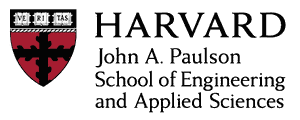

# CS1090A Introduction to Data Science

### Section 9 — Bayesian Logistic Regression, Sampling, and Hierarchical Models

<div style="background:#E8F1FF; border-left:6px solid #2563EB; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🎯 Objectives — what you should be able to do by the end</div>
<div>
<ul>
<li>Write the data-generating process for a dataset: what one observation is, its distribution, and which quantities are unknown parameters.</li>
<li>Choose a prior and defend it by translating it into the units of the problem.</li>
<li>Implement Metropolis-Hastings and read its trace plot and R-hat.</li>
<li>Fit the same model in PyMC and match each part of its output to what the hand-written sampler computed.</li>
<li>Compare posterior summaries with the maximum-likelihood estimate and a bootstrap.</li>
<li>Compute a posterior predictive probability from posterior draws.</li>
<li>Fit a hierarchical model and explain why some groups' estimates move more than others.</li>
</ul>
</div>
</div>

**Coloured boxes:** 🤔 commit to a prediction before running the code · 🏋️ write code (look for `# your code here`) · 💬 stop running cells and discuss · ⭐ the point of the exercise · 🧠 what to carry out of the room · 🔍 an appendix item to work through on your own afterwards.

Section 8 computed every posterior with a formula. Those formulas exist only for special pairs of
prior and likelihood, called **conjugate** pairs, where the posterior belongs to the same family
of distributions as the prior. A logistic regression with Normal priors on its coefficients is not
one of them. We can compute its posterior at any pair of coefficients, up to a constant, but there
is no formula for its mean, its standard deviation or its credible intervals (Section 8, Appendix
A3, shows why). This section solves that problem by drawing samples from the posterior. Once we
have a few thousand draws, every posterior summary is computed from them, the same way you would
summarize any column of numbers.

As in Section 8, every model has three pieces. For parameters $\theta$ and data $\mathbf y$:

- **Likelihood** $p(\mathbf y\mid\theta)$: how probable the observed data are for each value of the parameters.
- **Prior** $p(\theta)$: what we believe about the parameters before seeing the data.
- **Posterior** $p(\theta\mid\mathbf y)\propto p(\mathbf y\mid\theta)\,p(\theta)$: the likelihood times the prior, up to a constant that does not depend on $\theta$.

The section has four parts:

1. **Part 1** writes down a logistic regression model for whether a tumour is malignant: the likelihood, then a prior that we have to defend.
2. **Part 2** draws samples from that model's posterior with a sampler we write ourselves, Metropolis-Hastings, and checks whether the samples can be trusted.
3. **Part 3** fits the same model with PyMC, compares its output with ours, and uses the draws to predict for new tumours.
4. **Part 4** fits a **hierarchical model** to eight schools, where each school has its own effect and the eight effects share a common distribution.

## Setup

In [ ]:
# The first `import pymc` on a new machine can take 20 to 30 seconds while it compiles. That is normal.
import logging
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import seaborn as sns
from scipy.optimize import minimize
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
# PyMC prints a progress log for every fit; keep only errors. We count divergences ourselves.
logging.getLogger("pymc").setLevel(logging.ERROR)
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

### The tumour data

These are the breast tumour data from Section 7: 569 samples, each with a diagnosis (malignant or benign) and measurements of
the cell nuclei in a digitized image of the sample (Street, Wolberg and Mangasarian, 1993).
The data ships with scikit-learn. We use one predictor, `mean radius`: the average radius of
the nuclei in the image, in the image's units. Below, "radius" always means this feature. We
hold out 25% of the rows as a test set, which this section does not use; every model below is
fit on the development rows.

In [ ]:
# 1 = malignant. Hold out 25% as a test set, stratified on the diagnosis.
bunch = load_breast_cancer(as_frame=True)
y_all = (bunch.target == 0).astype(int).rename("malignant")
X_all = bunch.data[["mean radius"]]
X_dev, X_test, y_dev, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=109, stratify=y_all
)
print(f"development rows {len(X_dev)}, malignant {y_dev.sum()} ({y_dev.mean():.1%})")

We **standardize** the radius: subtract its development-set mean and divide by its standard
deviation (SD). The slope is then the change in log-odds per SD of radius, which makes a prior
easier to choose in Part 1. It also puts the intercept and the slope on similar scales, so in
Part 2 one proposal size suits both.

In [ ]:
# Standardize with the development rows' mean and SD
radius_mean, radius_sd = X_dev["mean radius"].mean(), X_dev["mean radius"].std()
radius_std = ((X_dev["mean radius"] - radius_mean) / radius_sd).to_numpy()
malignant = y_dev.to_numpy()
print(f"mean radius: average {radius_mean:.2f}, SD {radius_sd:.2f}")

## Part 1. Writing down a Bayesian model

### The data-generating process for one tumour

A Bayesian model starts as a description of how the data could have been produced, one
observation at a time. This description is the **data-generating process (DGP)**. It names
what one observation is, which probability distribution it follows, and which unknown
**parameters** that distribution depends on. Once the DGP is written down, the likelihood
follows from it: the probability of all the observations, as a function of the parameters.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 1: write the data-generating process (4 min)</div>
<div>
In the markdown cell below, write the DGP for tumour $i$ with standardized radius $x_i$ and
diagnosis $y_i$ (1 = malignant).
<ol>
<li>What distribution does $Y_i$ follow, and what is its parameter called?</li>
<li>How does that parameter depend on $x_i$? Write the formula.</li>
<li>List which symbols are data and which are unknown parameters.</li>
<li>Write the likelihood of all $n$ tumours as a product. What assumption lets you multiply?</li>
</ol>
</div>
</div>

**Your DGP:**

- $Y_i \mid \ldots \sim$
- $p_i =$
- data:
- parameters:
- likelihood:

### Choosing a prior for the coefficients

The conventional prior for logistic regression coefficients is a Normal distribution centered
at zero, $\beta_0, \beta_1 \sim N(0, \sigma_\beta^2)$, independently. Centering at zero means the
prior does not favour a positive or a negative association. The prior SD $\sigma_\beta$ is the
choice we have to make and defend.

A prior SD is hard to judge as a bare number, so we translate it into two quantities in the
units of the problem. First, 95% of a Normal prior's probability is within $\pm 1.96\,\sigma_\beta$ of zero.
Because $\beta_1$ is a change in log-odds per SD of radius, $e^{1.96\,\sigma_\beta}$ is the
upper end of the prior's central 95% interval for the **odds ratio per SD of radius**. The
prior gives only 2.5% probability to odds ratios above it.

In [ ]:
# Upper end of each prior's central 95% interval for the odds ratio per SD of radius
prior_sds = [0.5, 1.0, 2.5, 10.0]
for sd in prior_sds:
    print(f"prior SD {sd:>4}: 97.5th percentile of the odds ratio per SD of radius {np.exp(1.96 * sd):,.1f}")

Second, a **prior predictive simulation**: draw $\beta_0$ and $\beta_1$ from the prior, and
compute the probability of malignancy that the model then gives. This shows what the prior
claims about the data before any data are used. The cell below does this 4,000 times for a
tumour one SD above the average radius ($x = 1$).

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
With $\sigma_\beta = 10$, the prior allows very large coefficients. Where will most of the
prior predictive probabilities of malignancy fall: spread across 0 to 1, bunched near 0.5,
or piled up near 0 and 1?
</div>
</div>

In [ ]:
# Prior predictive: P(malignant) for a tumour at x = 1, under each prior SD
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True, constrained_layout=True)
for ax, sd in zip(axes, prior_sds):
    b0_prior, b1_prior = rng.normal(0, sd, 4000), rng.normal(0, sd, 4000)
    p_prior = 1 / (1 + np.exp(-(b0_prior + b1_prior * 1.0)))
    extreme = np.mean((p_prior < 0.01) | (p_prior > 0.99))
    ax.hist(p_prior, bins=25, range=(0, 1), color="#7E22CE", edgecolor="white")
    ax.set(title=f"prior SD {sd}\n{extreme:.0%} below 0.01 or above 0.99", xlabel="P(malignant) at x = 1")
axes[0].set_ylabel("prior draws")
plt.show()

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 1: defend a prior</div>
<div>
Choose one of the four prior SDs and defend it in two sentences, using both the odds-ratio
table and the prior predictive plots.
<ol>
<li>The two outputs pull in different directions. Which prior SD does each one favour?</li>
<li>Why should you not choose the prior SD by fitting the model first and looking at its slope?</li>
</ol>
</div>
</div>

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight</div>
<div>
A large prior SD on the log-odds scale puts most of the prior's probability on predictions
near 0 and 1, so it makes a strong claim about probabilities even though it looks
uninformative. Translating a prior into an odds ratio and into prior predictive probabilities
shows what it claims.
</div>
</div>

## Part 2. Sampling the posterior by hand: Metropolis-Hastings

### Why we need a sampler

With these Normal priors, the posterior of the logistic model is not another Normal
distribution, and there is no formula for its normalized density or for summaries such
as its mean. We can still evaluate $\text{likelihood} \times \text{prior}$, the posterior up to a
constant, at any $(\beta_0, \beta_1)$, and that is enough to draw samples from the posterior.

**Markov chain Monte Carlo (MCMC)** is a family of algorithms that produce a sequence of
parameter values, called a **chain**, in which each value depends only on the one before it.
After enough steps, the values in the chain are draws from the posterior, and any posterior
summary (a mean, an SD, an interval, a probability) is computed from the draws.

### The Metropolis-Hastings algorithm

**Metropolis-Hastings** is the MCMC algorithm from lecture. With a proposal that is
symmetric (a step up is as likely as the same step down), one iteration is:

1. **Propose** a new point by adding a random Normal step of SD `proposal_sd` to each coordinate of the current point.
2. **Accept** the proposal with probability $\min\left(1,\ \dfrac{p(\text{proposal} \mid \mathbf y)}{p(\text{current} \mid \mathbf y)}\right)$. A proposal with higher posterior density is always accepted; a lower one is accepted with probability equal to the ratio of the two densities.
3. If the proposal is rejected, **stay** at the current point.
4. **Record** the current point, and repeat.

Only the ratio of two posterior densities is needed, so the normalizing constant $p(\mathbf y)$
cancels and is never computed. On the log scale the accept test is
$\log u < \log p(\text{proposal}\mid\mathbf y) - \log p(\text{current}\mid\mathbf y)$ for a
uniform random number $u$ between 0 and 1.

### The log-posterior the sampler evaluates

The sampler needs one function: the log-posterior up to a constant, at any pair of
coefficients. It is the Bernoulli log-likelihood plus the two Normal log-priors with SD 2.5,
the prior chosen in Part 1. We also fit the maximum-likelihood estimate (MLE) with
scikit-learn, as in Section 7. The MLE plays no part in the sampler. We only use it to check
where the chains end up, since with 426 tumours and a wide prior the posterior should be
centred close to it.

In [ ]:
# The maximum-likelihood fit, for reference
mle = LogisticRegression(penalty=None).fit(radius_std.reshape(-1, 1), malignant)
mle_b0, mle_b1 = mle.intercept_[0], mle.coef_[0, 0]
print(f"MLE: intercept {mle_b0:.3f}, slope {mle_b1:.3f} per SD of radius")

In [ ]:
# The log-posterior up to a constant: Bernoulli log-likelihood plus Normal(0, prior_sd^2) log-priors
prior_sd = 2.5

def log_posterior(b):
    eta = b[0] + b[1] * radius_std
    log_lik = (malignant * eta - np.logaddexp(0, eta)).sum()     # sum of y*eta - log(1 + e^eta)
    log_prior = -(b @ b) / (2 * prior_sd**2)
    return log_lik + log_prior

print(f"log-posterior at the MLE {log_posterior(np.array([mle_b0, mle_b1])):.1f}, at (0, 0) {log_posterior(np.zeros(2)):.1f}")

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 2: the accept step (4 min)</div>
<div>
Complete the accept test in the cell below, on the log scale: draw a uniform random number $u$
between 0 and 1, and accept the proposal when $\log u$ is less than the log-posterior of the
proposal minus the log-posterior of the current point. Everything else in the sampler is provided.
<br><br>
The sampler's arguments have the same names as PyMC's <code style="background:rgba(0,0,0,0.06); color:#1F2937;">pm.sample</code>, so that Part 3 can
call PyMC with the same settings:
<ul>
<li><code style="background:rgba(0,0,0,0.06); color:#1F2937;">chains</code>: how many chains to run, each from its own random starting point.</li>
<li><code style="background:rgba(0,0,0,0.06); color:#1F2937;">tune</code>: how many iterations at the start of each chain are discarded. PyMC also adjusts its sampler during these iterations; ours only discards them.</li>
<li><code style="background:rgba(0,0,0,0.06); color:#1F2937;">draws</code>: how many iterations are kept per chain, after the <code style="background:rgba(0,0,0,0.06); color:#1F2937;">tune</code> iterations.</li>
<li><code style="background:rgba(0,0,0,0.06); color:#1F2937;">proposal_sd</code>: the SD of the Normal step added to each coordinate. This argument is ours; PyMC has no argument with this name.</li>
</ul>
A rejected proposal still records the current point again, so every iteration produces one row.
</div>
</div>

In [ ]:
def metropolis_hastings(chains=2, tune=1_000, draws=1_000, proposal_sd=0.2, seed=0):
    """Random-walk Metropolis-Hastings on log_posterior.

    Returns every iteration, shape (chains, tune + draws, 2), and the acceptance rate of each chain.
    """
    rng_mh = np.random.default_rng(seed)
    samples = np.empty((chains, tune + draws, 2))
    acceptance = np.zeros(chains)
    for c in range(chains):
        current = rng_mh.uniform(-3, 3, size=2)                  # each chain starts at a random point
        current_lp = log_posterior(current)
        accepted = 0
        for i in range(tune + draws):
            proposal = current + rng_mh.normal(0, proposal_sd, size=2)  # 1. propose
            proposal_lp = log_posterior(proposal)
            # your code here
            log_u = ...                                           # log of a uniform random number in (0, 1)
            if log_u < ...:                                       # 2. accept: compare with the log of the ratio
                current, current_lp = proposal, proposal_lp
                accepted += 1
            samples[c, i] = current                              # 3-4. record (moved or not)
        acceptance[c] = accepted / (tune + draws)
    return samples, acceptance


samples, acceptance = metropolis_hastings(chains=2, tune=1_000, draws=1_000, proposal_sd=0.2)
print(f"samples shape {samples.shape}, acceptance rate per chain {acceptance.round(2)}")

An acceptance rate of 0.56 means that 56% of the proposals were accepted. In the other 44% of
iterations the chain stayed where it was and recorded the same point again.

### Burn-in: discarding the start of each chain

Each chain starts at a random point, which may be far from the posterior, so its first
iterations are not posterior draws. Discarding them is called **burn-in**. The plot shows the
first 300 iterations of both chains for the slope.

In [ ]:
# The first 300 iterations of each chain: both travel from their starting points to the same region
fig, ax = plt.subplots(figsize=(10, 3))
for c in range(samples.shape[0]):
    ax.plot(samples[c, :300, 1], linewidth=0.8, label=f"chain {c}")
ax.axhline(mle_b1, color="#DC2626", linestyle="--", linewidth=1, label="MLE")
ax.set(xlabel="iteration", ylabel="slope", title="the start of each chain")
ax.legend()
plt.show()

In [ ]:
# Keep only the iterations after tune, as pm.sample does
tune = 1_000
draws_mh = samples[:, tune:, :]                     # shape (chains, draws, 2)
print(f"kept draws: {draws_mh.shape}")

### The trace plot

A **trace plot** shows, for each parameter, the distribution of each chain's kept draws (left)
and the draws in the order they were made (right). Two chains that have reached the posterior
give overlapping densities on the left and two overlapping bands of noise around the same
level, with no trend, on the right. PyMC's `az.plot_trace` draws the same two panels.

In [ ]:
# A trace plot drawn by hand, in the layout PyMC uses
def plot_trace_by_hand(draws, names=("b0", "b1")):
    fig, axes = plt.subplots(len(names), 2, figsize=(12, 2.3 * len(names)), constrained_layout=True)
    for j, name in enumerate(names):
        for c in range(draws.shape[0]):
            sns.kdeplot(draws[c, :, j], ax=axes[j, 0], linewidth=1)
            axes[j, 1].plot(draws[c, :, j], linewidth=0.5, alpha=0.8)
        axes[j, 0].set(title=name, xlabel="", ylabel="")
        axes[j, 1].set(title=name, xlabel="draw", ylabel="")
    plt.show()

plot_trace_by_hand(draws_mh)

### R-hat: comparing the chains

If every chain has reached the posterior, the chains should agree with each other: their means
should be close, and each chain's draws should be as spread out as all the draws pooled together.
**R-hat** measures this. With $m$ chains of $n$ draws each, let $W$ be the average of the $m$
within-chain variances, and let $B$ be the variance of the $m$ chain means. Then

$$\hat R = \sqrt{\frac{\frac{n-1}{n} W + B}{W}}.$$

When the chains agree, $B$ is small compared with $W$ and $\hat R$ is close to 1. When the
chains sit in different places, $B$ is large and $\hat R$ is above 1. A common rule is to use the
draws only when $\hat R$ is below 1.01. This is the classical Gelman-Rubin R-hat. ArviZ, which PyMC
uses for summaries, computes a refined version (it splits each chain in half and works with
ranks), which gives similar values when the chains are well behaved.

In [ ]:
# R-hat from the formula, and a summary table in the layout of az.summary
def r_hat(chains_draws):
    """chains_draws has shape (chains, draws) for one parameter."""
    m, n = chains_draws.shape
    within = chains_draws.var(axis=1, ddof=1).mean()             # W
    between = chains_draws.mean(axis=1).var(ddof=1)              # B
    return np.sqrt(((n - 1) / n * within + between) / within)


def summary_by_hand(draws, names=("b0", "b1")):
    rows = {}
    for j, name in enumerate(names):
        d = draws[:, :, j]
        rows[name] = {"mean": d.mean(), "sd": d.std(), "2.5%": np.percentile(d, 2.5),
                      "97.5%": np.percentile(d, 97.5), "r_hat": r_hat(d)}
    return pd.DataFrame(rows).T


summary_by_hand(draws_mh).round(3)

The `2.5%` and `97.5%` columns are a 95% **credible interval**: 95% of the posterior draws fall
between them. Both R-hat values are below 1.01. The next cell shows that the same formula does flag
the start of the chains, before burn-in was discarded.

In [ ]:
# R-hat before and after burn-in, for the slope
print(f"R-hat, first 200 iterations of each chain (before burn-in): {r_hat(samples[:, :200, 1]):.3f}")
print(f"R-hat, the kept draws:                                      {r_hat(draws_mh[:, :, 1]):.3f}")

In the first 200 iterations the two chains are still travelling from their different starting
points, so their means differ and R-hat is 1.10. On the kept draws they overlap, and R-hat is 1.00.

### Effective sample size

Consecutive draws from Metropolis-Hastings are correlated: after a rejection the chain repeats
the same value, and after an acceptance it has moved only a short distance. When consecutive
draws are positively correlated, 2,000 of them estimate the posterior mean less precisely than
2,000 independent draws would. The **effective sample size (ESS)** is the number of independent
draws that would give the same precision. We compute it with ArviZ's `az.ess` rather than
writing the formula.

In [ ]:
# ESS of our kept draws, for each parameter
pd.Series({name: az.ess(draws_mh[:, :, j]) for j, name in enumerate(["b0", "b1"])}, name="ess").round(0)

The 2,000 kept draws of the slope are worth about 82 independent draws, and those of the intercept
about 333. Keep these numbers in mind: Part 3 compares them with PyMC's.

### Choosing the proposal size

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
The cell below runs the sampler with proposal SDs 0.02, 0.2 and 2.0. Which will accept the
largest share of its proposals? Which will give the largest ESS?
</div>
</div>

In [ ]:
# Three proposal SDs, same settings otherwise: acceptance rate, trace of the slope, R-hat, ESS
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
size_rows = {}
for ax, size in zip(axes, [0.02, 0.2, 2.0]):
    s, acc = metropolis_hastings(chains=2, tune=1_000, draws=1_000, proposal_sd=size)
    kept = s[:, 1_000:, 1]
    for c in range(2):
        ax.plot(kept[c], linewidth=0.6, alpha=0.8)
    ax.set(ylabel="slope", title=f"proposal SD {size}: acceptance rate {acc.mean():.2f}")
    size_rows[size] = {"acceptance rate": acc.mean(), "slope mean": kept.mean(), "slope sd": kept.std(),
                       "r_hat": r_hat(kept), "ess": az.ess(kept)}
axes[-1].set_xlabel("draw (after tune)")
plt.show()
pd.DataFrame(size_rows).T.rename_axis("proposal SD").round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 2: reading the chains</div>
<div>
<ol>
<li>Proposal SD 0.02 accepts most proposals and 2.0 almost none. Describe what each trace looks like and why each explores the posterior slowly.</li>
<li>Which column of the table warns you about those two runs, and which column looks fine?</li>
<li>What would you change to get a usable result from the 0.02 run without changing its proposal SD?</li>
</ol>
</div>
</div>

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight</div>
<div>
Every number a sampler reports (a mean, an SD, an interval) is computed from its draws, so it
is only as good as the draws' coverage of the posterior. Look at the trace plot and R-hat before
reading anything else from a run. These checks catch the common failures; passing them does not
prove that the chains have explored the whole posterior.
</div>
</div>

## Part 3. The same model in PyMC

PyMC does what Part 2 did. We write the model, one line per line of the DGP and the prior, and
`pm.sample` runs the chains, discards the `tune` iterations and returns the kept draws. Two
things differ from our sampler. PyMC's default algorithm, **NUTS**, uses the gradient of the
log-posterior to propose points far from the current one that are still likely to be accepted
(Appendix A1 describes it). And during `tune`, PyMC adjusts the sampler's step size, which we
chose by hand.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 3: the model in PyMC (3 min)</div>
<div>
Complete the model in the cell below.
<ol>
<li>Normal priors on <code style="background:rgba(0,0,0,0.06); color:#1F2937;">b0</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">b1</code>: <code style="background:rgba(0,0,0,0.06); color:#1F2937;">pm.Normal("b0", mu=0, sigma=prior_sd)</code>.</li>
<li>The log-odds for every development tumour: <code style="background:rgba(0,0,0,0.06); color:#1F2937;">eta = b0 + b1 * radius_std</code>.</li>
<li>The likelihood: <code style="background:rgba(0,0,0,0.06); color:#1F2937;">pm.Bernoulli("malignant", logit_p=eta, observed=malignant)</code>. The argument <code style="background:rgba(0,0,0,0.06); color:#1F2937;">logit_p</code> takes log-odds and applies the logistic function for you.</li>
</ol>
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">pm.sample</code> is called with the same <code style="background:rgba(0,0,0,0.06); color:#1F2937;">chains</code>, <code style="background:rgba(0,0,0,0.06); color:#1F2937;">tune</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">draws</code> as our sampler.
</div>
</div>

In [ ]:
with pm.Model() as logistic_model:
    # your code here
    b0 = pm.Normal("b0", mu=..., sigma=...)                    # prior on the intercept
    b1 = ...                                                   # prior on the slope
    eta = ...                                                  # log-odds for every development tumour
    pm.Bernoulli("malignant", logit_p=..., observed=...)       # the likelihood
    idata = pm.sample(chains=2, tune=1_000, draws=1_000, random_seed=109, progressbar=False)

print(f"posterior draws: {idata.posterior.sizes['chain']} chains x {idata.posterior.sizes['draw']} draws")

In [ ]:
# PyMC's trace plot: the same two panels as ours
az.plot_trace(idata, var_names=["b0", "b1"], figsize=(12, 4.6))
plt.tight_layout()
plt.show()

`az.summary` reports what our table did, with ArviZ's version of R-hat, and two ESS columns:
`ess_bulk` for summaries of the middle of the distribution (the mean, the median) and `ess_tail`
for the tails, which interval endpoints depend on. When consecutive draws are negatively
correlated, as NUTS's often are, the ESS can be larger than the number of draws.

The `hdi_2.5%` and `hdi_97.5%` columns are a 95% **highest-density interval (HDI)**: the
narrowest interval holding 95% of the draws. Our table used the **equal-tailed interval**, from
the 2.5th to the 97.5th percentile. The two are close when the posterior is symmetric.

In [ ]:
# PyMC's summary
summary = az.summary(idata, var_names=["b0", "b1"], hdi_prob=0.95)
summary[["mean", "sd", "hdi_2.5%", "hdi_97.5%", "ess_bulk", "ess_tail", "r_hat"]]

In [ ]:
# Our sampler and PyMC side by side, every column computed the same way for both
pymc_draws = np.stack([idata.posterior["b0"].values, idata.posterior["b1"].values], axis=-1)
side_by_side = {}
for label, d in [("Metropolis-Hastings (ours)", draws_mh), ("PyMC (NUTS)", pymc_draws)]:
    table = summary_by_hand(d)
    table["ess"] = [az.ess(d[:, :, j]) for j in range(2)]
    side_by_side[label] = table
pd.concat(side_by_side).round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 3: our sampler and PyMC</div>
<div>
<ol>
<li>Which columns agree between the two samplers, and which one differs by a large factor?</li>
<li>Both made 2,000 kept draws. What does the ESS say about how precisely each set of draws estimates the posterior mean, and what in Checkpoint 2's traces explains the difference?</li>
</ol>
</div>
</div>

### The posterior beside the maximum-likelihood estimate and the bootstrap

The bootstrap estimates the sampling variability of the MLE: resample the development rows
with replacement, refit, and repeat. Its SD is a frequentist measure of uncertainty for the
slope. The posterior SD is the Bayesian one.

In [ ]:
# Bootstrap of the MLE slope: 300 resamples of the development rows (provided; skip if short of time)
rng = np.random.default_rng(1)
boot_slopes = []
for _ in range(300):
    rows = rng.integers(0, len(malignant), len(malignant))
    fit = LogisticRegression(penalty=None).fit(radius_std[rows].reshape(-1, 1), malignant[rows])
    boot_slopes.append(fit.coef_[0, 0])
boot_slopes = np.array(boot_slopes)

In [ ]:
# The slope three ways: estimate, spread, and a 95% interval
b1_draws = idata.posterior["b1"].values.ravel()
pd.DataFrame({
    "estimate": [b1_draws.mean(), mle_b1, boot_slopes.mean()],
    "SD": [b1_draws.std(), np.nan, boot_slopes.std()],
    "95% interval low": [np.percentile(b1_draws, 2.5), np.nan, np.percentile(boot_slopes, 2.5)],
    "95% interval high": [np.percentile(b1_draws, 97.5), np.nan, np.percentile(boot_slopes, 97.5)],
}, index=["posterior (PyMC)", "MLE", "bootstrap of the MLE"]).round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 4: three estimates of one slope</div>
<div>
<ol>
<li>The posterior mean is close to the MLE, and the posterior SD is close to the bootstrap SD. Why, given the prior SD of 2.5 and 426 tumours? What change to the data or the prior would make the posterior and the MLE disagree?</li>
<li>State what the 95% credible interval for the slope says, as an odds ratio per SD of radius.</li>
</ol>
</div>
</div>

### Predicting for a new tumour

For a new tumour with standardized radius $\tilde x$, each posterior draw $(\beta_0, \beta_1)$
gives a probability $\tilde p = 1/(1 + e^{-(\beta_0 + \beta_1 \tilde x)})$. The collection of
these $\tilde p$ is the posterior distribution of the new tumour's probability of malignancy.

The **posterior predictive distribution** goes one step further, to the new outcome itself:
$p(\tilde y \mid \mathbf y) = \int p(\tilde y \mid \theta)\, p(\theta \mid \mathbf y)\, d\theta$. To
sample from it, draw one outcome $\tilde y \sim \text{Bern}(\tilde p)$ for each posterior draw.
The share of those outcomes that are 1 estimates $P(\tilde Y = 1 \mid \mathbf y)$.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 4: a posterior predictive probability (3 min)</div>
<div>
For new tumours with mean radius 15 and 20:
<ol>
<li>compute <code style="background:rgba(0,0,0,0.06); color:#1F2937;">p_new</code>, an array with one row per posterior draw and one column per radius;</li>
<li>draw one outcome per draw and radius with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">rng.binomial(1, p_new)</code>, and store it in <code style="background:rgba(0,0,0,0.06); color:#1F2937;">y_new</code>.</li>
</ol>
The cell after it prints the summaries.
</div>
</div>

In [ ]:
radius_new = np.array([15.0, 20.0])
x_new = (radius_new - radius_mean) / radius_sd                 # standardized like the development rows
b0_draws = idata.posterior["b0"].values.ravel()                # 2,000 paired draws of the coefficients
b1_draws = idata.posterior["b1"].values.ravel()
rng = np.random.default_rng(2)

# your code here
p_new = ...                     # shape (2000, 2): use b0_draws[:, None] and b1_draws[:, None]
y_new = ...                     # one 0/1 outcome for each entry of p_new
print(p_new.shape, y_new.shape)

In [ ]:
# The probability of malignancy for each new tumour, and the predicted outcome
p_plugin = 1 / (1 + np.exp(-(b0_draws.mean() + b1_draws.mean() * x_new)))
pd.DataFrame({
    "mean of p": p_new.mean(axis=0),
    "p, 2.5%": np.percentile(p_new, 2.5, axis=0),
    "p, 97.5%": np.percentile(p_new, 97.5, axis=0),
    "share of y_new = 1": y_new.mean(axis=0),
    "p at posterior means": p_plugin,
}, index=[f"mean radius {r:.0f}" for r in radius_new]).round(3)

The first three columns summarize the 2,000 values of $\tilde p$ for each tumour: their mean and a
95% equal-tailed interval. The fourth is the share of simulated outcomes that are 1. The last
column is explained in the box after the plot.

In [ ]:
# Posterior distribution of the probability of malignancy for the two new tumours
fig, ax = plt.subplots(figsize=(8, 3.5))
for j, color in enumerate(["#2563EB", "#DC2626"]):
    ax.hist(p_new[:, j], bins=40, color=color, alpha=0.6, label=f"mean radius {radius_new[j]:.0f}")
ax.set(xlabel="P(malignant)", ylabel="posterior draws", title="posterior of the probability of malignancy")
ax.legend()
plt.show()

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight</div>
<div>
<ul>
<li>The posterior predictive probability that a new tumour is malignant is the average of $\tilde p$ over the posterior draws: transform every draw into a probability, then average. That is the first column.</li>
<li>The share of simulated outcomes equal to 1 estimates the same number, with some extra randomness from the simulation.</li>
<li>Plugging the posterior means of the coefficients into the logistic function (the last column) can give a different number, because the logistic function is curved: the probability at the average coefficients is not the average probability. The two are close here because the posterior is narrow. They can be far apart when the posterior is wide, as it is for a small group in a hierarchical model.</li>
</ul>
The interval for $\tilde p$ describes our uncertainty about a probability. The tumour's outcome itself is still 0 or 1.
</div>
</div>

## Part 4. Eight schools: a hierarchical model

### The eight-schools data

Eight high schools each ran an experiment on a coaching program for the verbal section of
the SAT, which is scored from 200 to 800 (Rubin, 1981). Each school compared coached and
uncoached students and reported two numbers:

- `effect` ($y_j$): the estimated effect of coaching on the school's average score, in points;
- `se` ($s_j$): the standard error of that estimate.

**Each row is a whole school's summary, not one student.** We do not have any individual
student's score. Only these eight pairs of numbers were published.

In [ ]:
# The eight schools: estimated coaching effect (SAT points) and its standard error
schools = pd.DataFrame({
    "effect": [28.0, 8.0, -3.0, 7.0, -1.0, 1.0, 18.0, 12.0],
    "se": [15.0, 10.0, 16.0, 11.0, 9.0, 11.0, 10.0, 18.0],
}, index=pd.Index(list("ABCDEFGH"), name="school"))
effect, se = schools["effect"].to_numpy(), schools["se"].to_numpy()
schools.T

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — the data-generating process for one school</div>
<div>
<ol>
<li>What is one observation in this dataset? How many observations are there?</li>
<li>Let $\alpha_j$ be school $j$'s true coaching effect, the one it would report with unlimited students. Write the distribution of $y_j$ given $\alpha_j$.</li>
<li>Why is it reasonable to treat $s_j$ as known rather than as a parameter?</li>
</ol>
</div>
</div>

### Three ways to estimate the eight effects

- **No pooling:** each school's effect is estimated from its own data only, so the estimate of $\alpha_j$ is $y_j$.
- **Complete pooling:** all schools have the same effect, $\alpha_j = \alpha_0$. The estimate of $\alpha_0$ is the average of the $y_j$ weighted by their **precisions** $1/s_j^2$, so that schools with smaller standard errors count more.
- **Partial pooling,** with a **hierarchical model:** each school has its own effect, and the eight effects are themselves drawn from a common distribution, $\alpha_j \sim N(\alpha_0, \sigma_\alpha^2)$. Here $\alpha_0$ is the average effect across schools and $\sigma_\alpha$ is how much the true effects differ between schools. The model estimates $\sigma_\alpha$ from the data.

In [ ]:
# Complete pooling: one effect for everyone, the precision-weighted average
weights = 1 / se**2
pooled_effect = (weights * effect).sum() / weights.sum()
pooled_se = np.sqrt(1 / weights.sum())
print(f"complete pooling: {pooled_effect:.1f} points (SE {pooled_se:.1f})")

### Priors for the average effect and the between-school SD

The hierarchical model needs priors for $\alpha_0$ and $\sigma_\alpha$, the parameters of the
common distribution; these are called **hyperpriors**.

- $\alpha_0 \sim N(0, 20^2)$: before seeing the data, we consider an average coaching effect beyond about 40 points in either direction implausible.
- $\sigma_\alpha \sim \text{HalfNormal}(10)$: a **half-Normal** distribution is a Normal centered at 0 with its negative half removed, since an SD cannot be negative. With scale 10, it puts about 95% of its probability on $\sigma_\alpha$ below 20 points ($1.96 \times 10$).

### Writing the model in non-centered form

Instead of drawing $\alpha_j$ from $N(\alpha_0, \sigma_\alpha^2)$ directly, we draw
$z_j \sim N(0, 1)$ and set $\alpha_j = \alpha_0 + \sigma_\alpha z_j$. Both give each $\alpha_j$ the
same distribution, so this is the same model, and PyMC samples it more reliably. Appendix A2 fits
both forms and shows the difference.

### Divergences in PyMC's sampler

PyMC's sampler moves through the parameters by simulating a path in many small numerical steps.
A **divergence** is an iteration where that simulation's numerical error became very large, which
happens where the posterior's shape changes sharply over a short distance. The sampler then does
not visit that region, so the summaries can be biased. A run we use should have no divergences;
Appendix A1 explains the mechanism.

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — reading the model</div>
<div>
The model below is provided. Match each line to a line of the DGP or a hyperprior above. Which
line is the likelihood, and where do the eight standard errors enter?
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">pm.Deterministic</code> records a quantity computed from other parameters, so that its draws
appear in the output. <code style="background:rgba(0,0,0,0.06); color:#1F2937;">target_accept=0.95</code> asks PyMC to tune a smaller step size than its
default (0.8), which makes divergences less likely (Appendix A1).
</div>
</div>

In [ ]:
# The non-centered hierarchical model for the eight schools
with pm.Model() as schools_model:
    alpha0 = pm.Normal("alpha0", mu=0, sigma=20)                  # hyperprior: average effect
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)          # hyperprior: SD of true effects
    z = pm.Normal("z", mu=0, sigma=1, shape=8)                    # one standard-Normal offset per school
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * z)   # each school's true effect
    pm.Normal("effect", mu=alpha, sigma=se, observed=effect)      # likelihood: y_j ~ N(alpha_j, s_j^2)
    # target_accept=0.95: tune a smaller step size than the default 0.8
    idata_schools = pm.sample(chains=2, tune=1_000, draws=1_000, target_accept=0.95,
                              random_seed=109, progressbar=False)

In [ ]:
# Diagnostics first, then the two hyperparameters
schools_summary = az.summary(idata_schools, var_names=["alpha0", "sigma_alpha", "alpha"], hdi_prob=0.95)
print(f"divergences: {int(idata_schools.sample_stats['diverging'].sum())}, "
      f"largest R-hat: {schools_summary['r_hat'].max():.2f}, smallest ESS: {schools_summary['ess_bulk'].min():.0f}")
sigma_alpha_draws = idata_schools.posterior["sigma_alpha"].values.ravel()
print(f"P(sigma_alpha < 2 points) = {(sigma_alpha_draws < 2).mean():.2f}")
schools_summary.loc[["alpha0", "sigma_alpha"], ["mean", "sd", "hdi_2.5%", "hdi_97.5%"]]

Check the printed line before reading the table: no divergences, R-hat no larger than 1.01 and an
ESS in the hundreds for every parameter mean the run passes the checks from Parts 2 and 3. The
exact values differ a little from one computer to another, because floating-point arithmetic
does; the conclusions should not.

### The shrinkage plot

**Shrinkage** is the movement of each group's estimate from its own data (no pooling) toward
the common average. If $\alpha_0$ and $\sigma_\alpha$ were known, school $j$'s posterior mean
would be a weighted average of its own report and the common average:

$$E(\alpha_j \mid y_j) = \frac{\sigma_\alpha^2}{\sigma_\alpha^2 + s_j^2}\, y_j + \frac{s_j^2}{\sigma_\alpha^2 + s_j^2}\, \alpha_0.$$

A larger standard error $s_j$, or a smaller $\sigma_\alpha$, puts more weight on $\alpha_0$. How
far a school moves in points also depends on how far its report starts from $\alpha_0$. The
fitted model averages this formula over the posterior draws of $\alpha_0$ and $\sigma_\alpha$.

The plot below shows each school's reported effect on the left and its posterior mean on the
right, and the 95% intervals of both.

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
School A reported an effect of 28 points with a standard error of 15. Will its posterior mean
be close to 28, close to the complete-pooling estimate, or in between? Which school do you
expect to move the least?
</div>
</div>

In [ ]:
# Each school's reported effect against its posterior mean, with 95% intervals
alpha_draws = idata_schools.posterior["alpha"].values.reshape(-1, 8)
schools["posterior mean"] = alpha_draws.mean(axis=0)
schools["moved"] = schools["posterior mean"] - schools["effect"]
alpha0_mean = float(idata_schools.posterior["alpha0"].mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for name, row in schools.iterrows():
    ax1.plot([0, 1], [row["effect"], row["posterior mean"]], color="#4B5563", marker="o")
    nudge = {"B": 3, "D": -9}.get(name, 0)                    # B and D are 1 point apart
    ax1.annotate(f"{name} (se {row['se']:.0f})", (0, row["effect"]), xytext=(-70, -3 + nudge), textcoords="offset points")
ax1.axhline(alpha0_mean, color="#7E22CE", linestyle=":", label="posterior mean of alpha0")
ax1.set(xticks=[0, 1], xticklabels=["reported effect\n(no pooling)", "posterior mean\n(partial pooling)"],
        xlim=(-0.4, 1.15), ylabel="coaching effect (points)", title="shrinkage toward the average")
ax1.legend(loc="upper right")

ypos = np.arange(8)
low, high = np.percentile(alpha_draws, [2.5, 97.5], axis=0)
ax2.errorbar(effect, ypos + 0.15, xerr=1.96 * se, fmt="o", color="#D97706", label="reported effect +/- 1.96 se")
ax2.errorbar(schools["posterior mean"], ypos - 0.15,
             xerr=[schools["posterior mean"] - low, high - schools["posterior mean"]],
             fmt="o", color="#7E22CE", label="posterior mean, 95% credible interval")
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set(yticks=ypos, yticklabels=schools.index, xlabel="coaching effect (points)", title="intervals by school")
ax2.invert_yaxis()
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
plt.show()
schools.round(1)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 5: what the hierarchical model did</div>
<div>
<ol>
<li>School A moved the most. Give the two reasons, one about its reported effect and one about its standard error.</li>
<li>School E reported −1 with the smallest standard error, 9. Compare how far it moved with School C, which reported −3 with a standard error of 16. Why the difference?</li>
<li>What would the model give if $\sigma_\alpha$ were 0? If $\sigma_\alpha$ were very large? Do the data allow very small between-school variation? Use the printed $P(\sigma_\alpha < 2)$.</li>
</ol>
</div>
</div>

### Hierarchical models for individual 0/1 observations with a group label

Here each row is a school's summary. When each
row is one person with a 0/1 outcome and a group label (one basketball shot and the player who
took it, say), the likelihood becomes Bernoulli, and an integer array `group` with one entry per
row picks out each row's group effect:
`pm.Bernoulli("y", logit_p=alpha[group], observed=y)`. A predictor shared by all groups adds a
fixed slope: `logit_p=alpha[group] + beta * x`. Appendix A3 fits this version.

<div style="background:#F3F4F6; border-left:6px solid #4B5563; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🧠 Takeaways — four things to remember</div>
<div>
<ol>
<li><strong>The data-generating process states what one observation is, which distribution it follows, and which parameters that distribution depends on.</strong> The likelihood and every line of the PyMC model are written from it, so write it before writing code. In the eight-schools data one observation is a school's summary, not a student.</li>
<li><strong>Defend a prior by translating it into the units of the problem.</strong> An odds ratio, a number of SAT points, or a prior predictive simulation shows what the prior claims. A large prior SD on log-odds puts most predicted probabilities near 0 and 1.</li>
<li><strong>An MCMC sampler produces a sequence of draws from the posterior, and every posterior summary is computed from those draws.</strong> Metropolis-Hastings proposes a random step and accepts it with probability min(1, posterior ratio). PyMC's NUTS does the same job, and its consecutive draws are much less correlated, so it gets a larger ESS from the same number of draws. Before using any draws, check four things: the chains overlap in the trace plot, R-hat is below 1.01, the ESS is in the hundreds, and there are no divergences. These checks catch common failures, but passing them does not prove that the chains explored the whole posterior.</li>
<li><strong>A hierarchical model estimates each group's effect as a weighted average of the group's own estimate and the common average.</strong> The weight on the common average is larger when the group's standard error is large or the between-group SD is small, so imprecise groups are pulled most of the way.</li>
</ol>
<p><strong>Final check:</strong> a ninth school reported an effect of 40 points with a standard error of 30. If we refit the hierarchical model with nine schools, will its posterior mean be closer to 40 or to the average? Why?</p>
</div>
</div>

---

## Appendix: things to try later

**Nothing below is expected during section.** Each item is a 🔍 Explore box: the code below it
is provided and runs as-is, and the work is reading the output and answering the questions.
Every item has a worked answer in the solutions notebook.

- **A1**: Hamiltonian Monte Carlo and NUTS, the algorithm PyMC uses, and what a divergence is.
- **A2**: the centered and non-centered forms of the eight-schools model.
- **A3**: a hierarchical logistic model on individual 0/1 observations with a group index.
- **A4**: checking the sampler against a posterior with a formula, for linear regression.
- **A5**: how much the prior on the between-school SD changes the eight-schools answer.
- **A6**: predicting the effect at a ninth school.

### A1. Hamiltonian Monte Carlo and NUTS, the sampler in PyMC

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A1</div>
<div>
<p>Metropolis-Hastings proposes a random step in any direction, so most large steps land
somewhere with low posterior density and are rejected. <strong>Hamiltonian Monte Carlo
(HMC)</strong> uses the gradient of the log-posterior to make a long move that stays where the
posterior density is high. One HMC iteration from the current point $\theta$:</p>
<ol>
<li>Draw a random <strong>momentum</strong> $r \sim N(0, I)$, one number per parameter.</li>
<li>Define the <strong>energy</strong> $H(\theta, r) = U(\theta) + K(r)$, the sum of a <strong>potential energy</strong> $U(\theta) = -\log p(\theta \mid \mathbf y)$ and a <strong>kinetic energy</strong> $K(r) = \tfrac12 r^\top r$. Points with high posterior density have low potential energy.</li>
<li>Move $(\theta, r)$ along the path that keeps $H$ constant. This path cannot be computed exactly, so it is approximated by $L$ <strong>leapfrog steps</strong> of size $\varepsilon$: half a step of $r$ along the gradient of $\log p$, a full step of $\theta$ along $r$, half a step of $r$, repeated. Following the gradient bends the path toward high posterior density.</li>
<li>Accept the end point with probability $\min(1, e^{-\Delta H})$, where $\Delta H$ is the change in energy along the path. An exact path would have $\Delta H = 0$ and always be accepted; $\Delta H$ is the error the leapfrog steps made.</li>
</ol>
<p>(The usual picture is a ball rolling on a surface whose height is $-\log p$: the momentum
carries it across the surface, and it speeds up going downhill into high-density regions.)</p>
<p><strong>A divergence</strong> is an iteration where the energy error became very large:
PyMC flags one when $\Delta H$ exceeds 1000 at any leapfrog step of a path (our code below checks
only the end of the path). It happens when $\varepsilon$ is too large for how sharply the
posterior curves at that place: the leapfrog steps overshoot and the energy error grows without
bound. An ordinary rejection, with a moderate $\Delta H$, is not a divergence; a divergence is a
failure of the numerical simulation itself.</p>
<p>One $\varepsilon$ serves the whole posterior. If the posterior is wide in some regions and
very narrow in others, the $\varepsilon$ tuned for the wide regions is too large in the narrow
ones, paths entering them diverge, and the draws under-represent those regions. That is why
divergences can bias the summaries, not only slow the sampler, and why a run with divergences is
not trusted even when R-hat looks fine. In the centered eight-schools model the narrow region is
where $\sigma_\alpha$ is small and all the $\alpha_j$ must sit close to $\alpha_0$ (Appendix A2).
Raising <code>target_accept</code> shrinks $\varepsilon$ and can reduce divergences, but
rewriting the model so the narrow region disappears, as the non-centered form does here, is
usually the better fix. Neither zero divergences nor non-centering proves that the sampler has
explored the whole posterior.</p>
<p><strong>NUTS</strong> ("No-U-Turn Sampler") is the HMC variant PyMC uses. It chooses $L$
anew at each iteration: it doubles the path's length repeatedly (each doubling is one level of
<code>tree_depth</code>) until the path starts to turn back toward where it began, up to a maximum
of $2^{10}$ steps. Our code below uses a fixed-length path with $L$ drawn at random, which is plain
HMC, not NUTS. The PyMC settings map onto these pieces:</p>
<ul>
<li><code>tune</code>: iterations in which PyMC adjusts $\varepsilon$ and rescales each parameter (a "mass matrix") so one step size suits all of them; then they are discarded.</li>
<li><code>target_accept</code> (default 0.8): the average acceptance probability $\varepsilon$ is tuned toward. Raising it to 0.9 or 0.95 makes $\varepsilon$ smaller, which removes divergences caused by a too-large step at the cost of more leapfrog steps per iteration.</li>
<li><code>sample_stats</code>: per-iteration records, including <code>step_size</code> ($\varepsilon$), <code>n_steps</code> ($L$), <code>tree_depth</code>, <code>energy_error</code> and <code>diverging</code>. Iterations that reach the maximum tree depth (<code>reached_max_treedepth</code>) are a separate warning: the path was cut off before it turned back, so the sampler moved less far than it wanted.</li>
</ul>
<p>The cells below implement HMC by hand on Part 2's posterior, draw one HMC path beside 20
Metropolis-Hastings iterations, run HMC with three step sizes $\varepsilon$, and read PyMC's own
<code>sample_stats</code>.</p>
<ol>
<li>How far does one HMC iteration move compared with one Metropolis-Hastings iteration? How does that relate to the ESS difference in Checkpoint 3?</li>
<li>As $\varepsilon$ grows, what happens to the energy error, the acceptance rate and the number of divergences?</li>
<li>PyMC's step size is much larger than any $\varepsilon$ in the table, yet it reports no divergences. What did tuning do that our sampler does not?</li>
</ol>
</div>
</div>

In [ ]:
# HMC by hand: the gradient of the log-posterior, leapfrog steps, and the accept test
X_design = np.column_stack([np.ones(len(radius_std)), radius_std])

def grad_log_posterior(b):
    p = 1 / (1 + np.exp(-(X_design @ b)))
    return X_design.T @ (malignant - p) - b / prior_sd**2


def hmc_iteration(theta, eps, n_leapfrog, rng_hmc):
    """One HMC iteration. Returns the new point, the path, and the energy error."""
    r = rng_hmc.normal(size=2)                                  # 1. random momentum
    h_start = -log_posterior(theta) + r @ r / 2                 # 2. energy at the start
    q, path = theta.copy(), [theta.copy()]
    r = r + eps / 2 * grad_log_posterior(q)                     # 3. leapfrog: half step of momentum
    for step_i in range(n_leapfrog):
        q = q + eps * r                                         #    full step of position
        path.append(q.copy())
        if step_i < n_leapfrog - 1:
            r = r + eps * grad_log_posterior(q)                 #    full step of momentum
    r = r + eps / 2 * grad_log_posterior(q)                     #    final half step of momentum
    energy_error = (-log_posterior(q) + r @ r / 2) - h_start
    if np.log(rng_hmc.random()) < -energy_error:                # 4. accept with prob min(1, e^-dH)
        theta = q
    return theta, np.array(path), energy_error

In [ ]:
# One HMC path against 20 Metropolis-Hastings iterations, over the posterior's contours
grid_b0, grid_b1 = np.meshgrid(np.linspace(-1.3, 0.0, 120), np.linspace(2.0, 4.8, 120))
grid_lp = np.array([log_posterior(np.array([u, v])) for u, v in zip(grid_b0.ravel(), grid_b1.ravel())])
grid_lp = grid_lp.reshape(grid_b0.shape)

start = np.array([-0.4, 2.6])
rng_hmc = np.random.default_rng(3)
_, hmc_path, _ = hmc_iteration(start, eps=0.05, n_leapfrog=25, rng_hmc=rng_hmc)

rng_walk = np.random.default_rng(3)
walk, current = [start.copy()], start.copy()
for _ in range(20):
    proposal = current + rng_walk.normal(0, 0.2, size=2)       # proposal SD 0.2, as in Part 2
    if np.log(rng_walk.random()) < log_posterior(proposal) - log_posterior(current):
        current = proposal
    walk.append(current.copy())
walk = np.array(walk)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.contour(grid_b0, grid_b1, grid_lp - grid_lp.max(), levels=[-8, -4.5, -2, -0.5], colors="#9CA3AF", linestyles="solid")
ax.plot(walk[:, 0], walk[:, 1], "o-", color="#D97706", markersize=3, label="20 Metropolis-Hastings iterations")
ax.plot(hmc_path[:, 0], hmc_path[:, 1], "o-", color="#7E22CE", markersize=3, label="1 HMC iteration (25 leapfrog steps)")
ax.scatter(*start, color="black", zorder=3, label="start")
ax.set(xlabel="b0 (intercept)", ylabel="b1 (slope)", title="how far each sampler moves")
ax.legend(fontsize=9)
plt.show()

In [ ]:
# HMC with three step sizes: energy error, acceptance and divergences (Delta H > 1000, PyMC's threshold)
def hmc(eps, n_iterations=1_000, seed=0):
    rng_run = np.random.default_rng(seed)
    theta, draws_hmc, errors = np.array([mle_b0, mle_b1]), [], []
    for _ in range(n_iterations):
        new_theta, _, err = hmc_iteration(theta, eps, rng_run.integers(10, 31), rng_run)
        errors.append(err)
        draws_hmc.append(new_theta)
        theta = new_theta
    return np.array(draws_hmc), np.array(errors)

hmc_rows = {}
for eps in [0.05, 0.15, 0.3]:
    d, errors = hmc(eps)
    moved = np.any(np.diff(d, axis=0) != 0, axis=1)
    hmc_rows[eps] = {"median |energy error|": np.median(np.abs(errors)), "acceptance rate": moved.mean(),
                     "divergences": int((errors > 1000).sum()), "slope mean": d[:, 1].mean(), "slope sd": d[:, 1].std()}
pd.DataFrame(hmc_rows).T.rename_axis("step size").round(3)

In [ ]:
# PyMC's own record of each NUTS iteration in Part 3's fit
stats = idata.sample_stats
pd.Series({
    "step size after tuning": float(stats["step_size"].mean()),
    "mean leapfrog steps per iteration": float(stats["n_steps"].mean()),
    "mean tree depth": float(stats["tree_depth"].mean()),
    "mean acceptance probability": float(stats["acceptance_rate"].mean()),
    "divergences": int(stats["diverging"].sum()),
}).round(3)

### A2. Centered and non-centered forms of the eight-schools model

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A2</div>
<div>
<p>The <strong>centered</strong> form writes the model as it is stated,
$\alpha_j \sim N(\alpha_0, \sigma_\alpha^2)$. When $\sigma_\alpha$ is small, every $\alpha_j$ must be
close to $\alpha_0$, and when it is large they can spread out, so the posterior is very narrow
in some places and very wide in others. One step size cannot work in both regions, and the
sampler reports divergences. The <strong>non-centered</strong> form samples $z_j$, whose
posterior has a similar width everywhere, and computes $\alpha_j$ from it.</p>
<ol>
<li>How many divergences does each form produce, and how do the ESS values for $\sigma_\alpha$ compare?</li>
<li>Do the two forms give similar posterior means? Which would you trust, and why?</li>
</ol>
</div>
</div>

In [ ]:
# The same model and priors, centered and non-centered
def fit_schools_form(centered):
    with pm.Model():
        alpha0_ = pm.Normal("alpha0", mu=0, sigma=20)
        sigma_alpha_ = pm.HalfNormal("sigma_alpha", sigma=10)
        if centered:
            alpha_ = pm.Normal("alpha", mu=alpha0_, sigma=sigma_alpha_, shape=8)
        else:
            alpha_ = alpha0_ + sigma_alpha_ * pm.Normal("z", mu=0, sigma=1, shape=8)
        pm.Normal("effect", mu=alpha_, sigma=se, observed=effect)
        return pm.sample(draws=1_000, tune=1_000, chains=2, target_accept=0.95,
                         random_seed=109, progressbar=False)

form_rows = {}
for label, centered in [("centered", True), ("non-centered", False)]:
    fitted = fit_schools_form(centered)
    s = az.summary(fitted, var_names=["alpha0", "sigma_alpha"])
    form_rows[label] = {"divergences": int(fitted.sample_stats["diverging"].sum()),
                        "alpha0 mean": s.loc["alpha0", "mean"], "sigma_alpha mean": s.loc["sigma_alpha", "mean"],
                        "ESS sigma_alpha": s.loc["sigma_alpha", "ess_bulk"], "R-hat sigma_alpha": s.loc["sigma_alpha", "r_hat"]}
pd.DataFrame(form_rows).T.round(2)

### A3. A hierarchical logistic model on individual observations

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A3</div>
<div>
<p>In the eight-schools data each row was a group's summary. More often each row is one
individual with a 0/1 outcome and a group label, as when each row is one basketball shot and
the group is the player. The model is then a hierarchical logistic regression,
$Y_{ij} \sim \text{Bern}(p_{ij})$ with $\ln\frac{p_{ij}}{1-p_{ij}} = \alpha_j$ and
$\alpha_j \sim N(\alpha_0, \sigma_\alpha^2)$. In PyMC, an integer array <code>group</code> with one
entry per row selects each row's group effect: <code>alpha[group]</code>.</p>
<p>The data below are simulated, twenty groups of very different sizes, so that the true rates
are known and each estimate can be checked against them.</p>
<ol>
<li>In the shrinkage plot, which groups moved most, and what do they have in common?</li>
<li>Which estimate has the smallest mean absolute error for the five smallest groups? For the five largest?</li>
</ol>
</div>
</div>

In [ ]:
# Twenty simulated groups with known true rates, one row per individual
sim_rng = np.random.default_rng(109)
sizes = np.sort(sim_rng.integers(5, 200, size=20))
true_rate = sim_rng.beta(4, 12, size=20)
group = np.repeat(np.arange(20), sizes)                       # each row's group, 0 to 19
outcome = sim_rng.binomial(1, true_rate[group])               # each row's 0/1 outcome
groups = pd.DataFrame({"n": sizes, "true rate": true_rate,
                       "raw rate": np.bincount(group, weights=outcome) / sizes})
pooled_rate = outcome.mean()

with pm.Model():
    alpha0_ = pm.Normal("alpha0", mu=0, sigma=2.5)
    sigma_alpha_ = pm.HalfNormal("sigma_alpha", sigma=1)
    z_ = pm.Normal("z", mu=0, sigma=1, shape=20)
    logit_p = pm.Deterministic("logit_p", alpha0_ + sigma_alpha_ * z_)
    pm.Bernoulli("outcome", logit_p=logit_p[group], observed=outcome)
    idata_groups = pm.sample(draws=1_000, tune=1_000, chains=2, target_accept=0.9,
                             random_seed=109, progressbar=False)

# Each group's posterior rate: transform every draw, then average
rate_draws = 1 / (1 + np.exp(-idata_groups.posterior["logit_p"].values.reshape(-1, 20)))
groups["partial pooling"] = rate_draws.mean(axis=0)
groups["complete pooling"] = pooled_rate
print(f"divergences: {int(idata_groups.sample_stats['diverging'].sum())}")

In [ ]:
# Shrinkage plot against group size, and mean absolute error against the truth
fig, ax = plt.subplots(figsize=(10, 4.5))
for _, g in groups.iterrows():
    ax.annotate("", xy=(g["n"], g["partial pooling"]), xytext=(g["n"], g["raw rate"]),
                arrowprops=dict(arrowstyle="->", color="#4B5563"))
ax.scatter(groups["n"], groups["raw rate"], color="#D97706", label="raw rate (no pooling)", zorder=3)
ax.scatter(groups["n"], groups["partial pooling"], color="#7E22CE", label="partial pooling", zorder=3)
ax.scatter(groups["n"], groups["true rate"], marker="x", color="#DC2626", label="true rate", zorder=3)
ax.axhline(pooled_rate, color="black", linestyle=":", label="complete pooling")
ax.set(xlabel="observations in the group", ylabel="rate", title="shrinkage depends on group size")
ax.legend(fontsize=9)
plt.show()

estimates = ["raw rate", "complete pooling", "partial pooling"]
def mean_abs_error(rows):
    return {e: (rows[e] - rows["true rate"]).abs().mean() for e in estimates}
pd.DataFrame({"all 20": mean_abs_error(groups), "5 smallest": mean_abs_error(groups.nsmallest(5, "n")),
              "5 largest": mean_abs_error(groups.nlargest(5, "n"))}).round(3)

### A4. Checking the sampler against a posterior with a formula

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A4</div>
<div>
<p>For linear regression with a known noise SD $\sigma$, no prior on the intercept and a prior
$\beta_1 \sim N(0, \sigma_{\beta_1}^2)$ on the slope, the posterior of the slope is Normal with</p>
$$\text{mean} = \frac{S_{xy}}{S_{xx} + \sigma^2/\sigma_{\beta_1}^2}, \qquad \text{SD} = \sqrt{\frac{\sigma^2 \sigma_{\beta_1}^2}{S_{xx}\sigma_{\beta_1}^2 + \sigma^2}},$$
<p>where $S_{xx} = \sum_i (x_i - \bar x)^2$ and $S_{xy} = \sum_i (x_i - \bar x)(y_i - \bar y)$.
This mean is also the ridge regression slope with penalty $\lambda = \sigma^2/\sigma_{\beta_1}^2$.
The cells fit simulated data (80 points, true slope 0.65, $\sigma = 7$) with a wide prior
($\sigma_{\beta_1} = 100$) and a narrow one ($\sigma_{\beta_1} = 0.12$), and compare the formula,
PyMC, ridge, and the OLS slope with its 95% confidence interval $\hat\beta_1 \pm 1.96\,\sigma/\sqrt{S_{xx}}$.</p>
<ol>
<li>Does PyMC reproduce the formula's mean and SD? Does ridge reproduce the posterior mean?</li>
<li>Under the wide prior, how do the 95% credible interval and the OLS confidence interval compare? Under the narrow prior?</li>
</ol>
</div>
</div>

In [ ]:
# Simulated regression data with a known noise SD
reg_rng = np.random.default_rng(110)
x_reg = reg_rng.normal(170, 8, 80)
sigma_noise = 7.0
y_reg = 175 + 0.65 * (x_reg - 170) + reg_rng.normal(0, sigma_noise, 80)
s_xx = ((x_reg - x_reg.mean())**2).sum()
s_xy = ((x_reg - x_reg.mean()) * (y_reg - y_reg.mean())).sum()
ols_slope = s_xy / s_xx
ols_half = 1.96 * sigma_noise / np.sqrt(s_xx)
print(f"OLS slope {ols_slope:.3f}, 95% confidence interval ({ols_slope - ols_half:.3f}, {ols_slope + ols_half:.3f})")

In [ ]:
# Formula, PyMC and ridge for two prior SDs on the slope
check_rows = {}
for slope_prior_sd in [100.0, 0.12]:
    post_mean = s_xy / (s_xx + sigma_noise**2 / slope_prior_sd**2)
    post_sd = np.sqrt(sigma_noise**2 * slope_prior_sd**2 / (s_xx * slope_prior_sd**2 + sigma_noise**2))
    with pm.Model():
        intercept = pm.Flat("intercept")                       # improper flat prior: every intercept weighted equally
        slope = pm.Normal("slope", mu=0, sigma=slope_prior_sd)
        pm.Normal("y", mu=intercept + slope * (x_reg - x_reg.mean()), sigma=sigma_noise, observed=y_reg)
        fitted = pm.sample(draws=2_000, tune=1_000, chains=2, random_seed=109, progressbar=False)
    slope_draws = fitted.posterior["slope"].values.ravel()
    ridge = Ridge(alpha=sigma_noise**2 / slope_prior_sd**2).fit(x_reg.reshape(-1, 1), y_reg)
    check_rows[f"prior SD {slope_prior_sd}"] = {
        "formula mean": post_mean, "PyMC mean": slope_draws.mean(), "ridge slope": ridge.coef_[0],
        "formula SD": post_sd, "PyMC SD": slope_draws.std(),
        "95% credible low": np.percentile(slope_draws, 2.5), "95% credible high": np.percentile(slope_draws, 97.5)}
pd.DataFrame(check_rows).T.round(3)

### A5. How much the prior on $\sigma_\alpha$ matters

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A5</div>
<div>
<p>Eight observations carry little information about how much eight schools differ, so the prior
on $\sigma_\alpha$ can affect the answer. The cell below refits the Part 4 model with half-Normal
scales of 5 and 25 and puts the results beside the scale-10 fit.</p>
<ol>
<li>How much do the posterior mean of $\sigma_\alpha$ and School A's posterior mean change across the three priors?</li>
<li>Why does the prior matter more here than it did for the tumour slope in Part 3?</li>
</ol>
</div>
</div>

In [ ]:
# Refit with two other prior scales for sigma_alpha
def fit_schools(scale):
    with pm.Model():
        alpha0_ = pm.Normal("alpha0", mu=0, sigma=20)
        sigma_alpha_ = pm.HalfNormal("sigma_alpha", sigma=scale)
        z_ = pm.Normal("z", mu=0, sigma=1, shape=8)
        pm.Deterministic("alpha", alpha0_ + sigma_alpha_ * z_)
        pm.Normal("effect", mu=alpha0_ + sigma_alpha_ * z_, sigma=se, observed=effect)
        return pm.sample(draws=1_000, tune=1_000, chains=2, target_accept=0.95,
                         random_seed=109, progressbar=False)

rows = {}
for scale, fitted in [(5, fit_schools(5)), (10, idata_schools), (25, fit_schools(25))]:
    s = az.summary(fitted, var_names=["sigma_alpha", "alpha"], hdi_prob=0.95)
    rows[f"HalfNormal({scale})"] = {"sigma_alpha mean": s.loc["sigma_alpha", "mean"],
                                    "sigma_alpha, upper end of 95% HDI": s.loc["sigma_alpha", "hdi_97.5%"],
                                    "school A posterior mean": s.loc["alpha[0]", "mean"]}
pd.DataFrame(rows).T.round(1)

### A6. Predicting the effect at a ninth school

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A6</div>
<div>
<p>A ninth school plans the same coaching program. Its true effect is a new draw from the common
distribution, $\tilde\alpha \sim N(\alpha_0, \sigma_\alpha^2)$, and if it runs an experiment with
a standard error of 10, its reported effect will be $\tilde y \sim N(\tilde\alpha, 10^2)$. Doing
this once for each posterior draw of $(\alpha_0, \sigma_\alpha)$ samples the posterior predictive
distribution.</p>
<ol>
<li>Why is the interval for the reported effect wider than the interval for the true effect?</li>
<li>A school board asks: "What is the probability that coaching helps at our school?" Which row and column answer that?</li>
</ol>
</div>
</div>

In [ ]:
# Posterior predictive for a new school: a true effect, then a reported effect with se 10
rng = np.random.default_rng(9)
alpha0_draws = idata_schools.posterior["alpha0"].values.ravel()
alpha_ninth = rng.normal(alpha0_draws, sigma_alpha_draws)
effect_ninth = rng.normal(alpha_ninth, 10)
pd.DataFrame({
    "mean": [alpha_ninth.mean(), effect_ninth.mean()],
    "95% interval low": [np.percentile(alpha_ninth, 2.5), np.percentile(effect_ninth, 2.5)],
    "95% interval high": [np.percentile(alpha_ninth, 97.5), np.percentile(effect_ninth, 97.5)],
    "P(> 0)": [(alpha_ninth > 0).mean(), (effect_ninth > 0).mean()],
}, index=["true effect at a ninth school", "its reported effect (se 10)"]).round(2)